In [1]:
import pandas as pd
import shutil 


In [32]:
df = pd.read_csv('~/Documents/MATLAB/imdb.csv')
df.head()

,dob_serial,photo_taken,age,full_path,gender,name,x1,y1,x2,y2,face_score,second_face_score,celeb_id
0,693726,1968,69,01/nm0000001_rm124825600_1899-5-10_1968.jpg,1.0,Fred Astaire,1072.926000,161.838000,1214.784000,303.696000,1.459693,1.118973,6488
1,693726,1970,71,01/nm0000001_rm3343756032_1899-5-10_1970.jpg,1.0,Fred Astaire,477.184000,100.352000,622.592000,245.760000,2.543198,1.852008,6488
2,693726,1968,69,01/nm0000001_rm577153792_1899-5-10_1968.jpg,1.0,Fred Astaire,114.969643,114.969643,451.686572,451.686572,3.455579,2.985660,6488
3,693726,1968,69,01/nm0000001_rm946909184_1899-5-10_1968.jpg,1.0,Fred Astaire,622.885506,424.217504,844.339008,645.671006,1.872117,NaN,6488
4,693726,1968,69,01/nm0000001_rm980463616_1899-5-10_1968.jpg,1.0,Fred Astaire,1013.859002,233.882042,1201.586128,421.609168,1.158766,NaN,6488


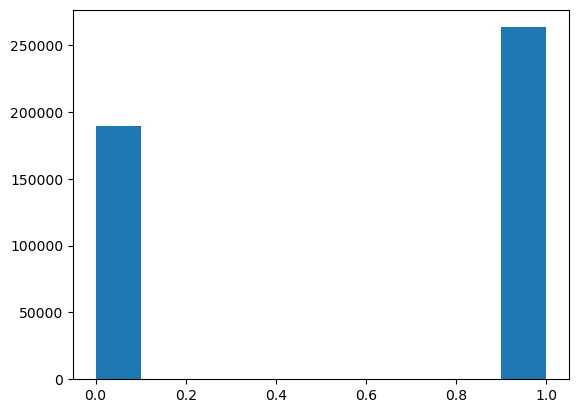

In [4]:
import matplotlib.pyplot as plt

plt.hist(x=df.gender)
plt.show()

In [33]:
df.gender.value_counts()

gender
1.0    263214
0.0    189047
Name: count, dtype: int64

In [34]:
df = df.copy()
df["gender"] = df["gender"].replace({1.0: "male", 0.0: "female"})
df["gender"].value_counts()
df = df.dropna(subset=['gender']).copy()
df.gender.value_counts(dropna=False)

gender
male      263214
female    189047
Name: count, dtype: int64

In [35]:
import shutil
from pathlib import Path

src_root = Path("../data/imdb_crop/imdb_crop")
dst_root = Path("../data/gender_dir")   
dst_root.mkdir(parents=True, exist_ok=True)

for full_path, gender in zip(df["full_path"], df["gender"]):
    src = src_root / full_path                  
    label_dir = dst_root / gender      
    label_dir.mkdir(parents=True, exist_ok=True)

    dst = label_dir / src.name                  
    shutil.copy2(src, dst)                      
